## Background Information

Accurate sales forecasting is essential for retail organizations as it supports effective inventory management, demand planning, resource allocation, and strategic decision-making. Retail sales are influenced by several factors, including promotions, holidays, customer transactions, store characteristics, and economic conditions, making demand prediction a complex task.This study utilizes historical retail sales data together with transactional, holiday, store, and oil price information to develop forecasting models and support inventory optimization through data-driven decision-making.

## Problem Statement

Retail businesses often face challenges in accurately forecasting future sales due to fluctuating customer demand, seasonal effects, promotional activities, and changing market conditions. Inaccurate forecasts can result in stock shortages, excess inventory, increased operational costs, and reduced customer satisfaction.

Although traditional forecasting models such as ARIMA are commonly used, they may be limited in capturing the complex and nonlinear relationships present in retail sales data. Therefore, there is a need to investigate and compare the effectiveness of ARIMA, Prophet, and LSTM models in forecasting retail sales demand and to utilize the forecast results for inventory optimization through safety stock and reorder point analysis.

## Objectives

General Objective

To develop and compare ARIMA, Prophet, and LSTM models for retail sales forecasting and utilize the best-performing model to support inventory optimization.

Specific Objectives

To preprocess and integrate retail sales, transaction, store, holiday, and oil price datasets for forecasting analysis.

To explore and analyze historical sales patterns, trends, seasonality, and factors influencing sales performance.

To develop and evaluate ARIMA, Prophet, and LSTM forecasting models using MAE, RMSE, and R² performance metrics.

To identify the best-performing forecasting model for predicting future retail sales demand.

To utilize forecasted sales demand to determine appropriate safety stock and reorder point levels for inventory optimization.

To provide data-driven recommendations that support effective sales forecasting and inventory management in retail organizations

# Importing Libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

# Loading dataset

In [13]:
from pathlib import Path

train = pd.read_csv("train.csv")
oil = pd.read_csv("oil.csv")
stores = pd.read_csv("stores.csv")
# The Kaggle file is usually named "holidays_events.csv" (plural),
# and it may live in a subfolder instead of the current working directory.
candidates = [
    Path("holidays_events.csv"),
    Path("holidays_event.csv"),
    Path("data/holidays_events.csv"),
    Path("data/holidays_event.csv"),
]

holiday = None
for path in candidates:
    if path.exists():
        holiday = pd.read_csv(path)
        break

if holiday is None:
    raise FileNotFoundError(
        "Could not find holidays_events.csv (or holidays_event.csv). "
        "Check the file name/path in your project folder."
    )
transactions = pd.read_csv("transactions.csv")



# Data Structure

In [37]:
print(train.shape)
print(oil.shape)
print(stores.shape)
print(holiday.shape)
print(transactions.shape)


(3000888, 6)
(1218, 2)
(54, 5)
(350, 6)
(83488, 3)


# Data Preprocessing

In [38]:
print("Train missing:\n", train.isnull().sum())
print("Oil missing:\n", oil.isnull().sum())
print("Stores missing:\n", stores.isnull().sum())
print("Holiday missing:\n", holiday.isnull().sum())
print("Transactions missing:\n", transactions.isnull().sum())


Train missing:
 id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
Oil missing:
 date          0
dcoilwtico    0
dtype: int64
Stores missing:
 store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64
Holiday missing:
 date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64
Transactions missing:
 date            0
store_nbr       0
transactions    0
dtype: int64


In [39]:
# Filling for missing values in oil prices using forward fill and backward fill
oil["dcoilwtico"] = (
    oil["dcoilwtico"]
    .ffill()
    .bfill()
)

In [41]:
oil.isnull().sum()

date          0
dcoilwtico    0
dtype: int64

Found 43 missing oil prices in oil csv and filled the missing oil price values with forward and backward fill

Duplicates

In [42]:
print("Train duplicates:", train.duplicated().sum())

print("Oil duplicates:", oil.duplicated().sum())

print("Stores duplicates:", stores.duplicated().sum())

print("Transactions duplicates:", transactions.duplicated().sum())

print("Holiday duplicates:", holiday.duplicated().sum())

Train duplicates: 0
Oil duplicates: 0
Stores duplicates: 0
Transactions duplicates: 0
Holiday duplicates: 0


Columns

In [43]:
train.columns
oil.columns
stores.columns
transactions.columns
holiday.columns


Index(['date', 'type', 'locale', 'locale_name', 'description', 'transferred'], dtype='str')

In [44]:
# Convert the date columns to datetime format
train["date"] = pd.to_datetime(train["date"])
oil["date"] = pd.to_datetime(oil["date"])
transactions["date"] = pd.to_datetime(transactions["date"])
holiday["date"] = pd.to_datetime(holiday["date"])

In [45]:
# Create a new column in the holiday DataFrame to indicate whether a date is a holiday or not
holiday["is_holiday"] = 1

holiday_flag = (
    holiday[["date", "is_holiday"]]
    .drop_duplicates()
)

In [46]:
holiday_flag.head()

,date,is_holiday
0,2012-03-02,1
1,2012-04-01,1
2,2012-04-12,1
3,2012-04-14,1
4,2012-04-21,1


Merging

In [53]:
df = train.merge(
    stores,
    on="store_nbr",
    how="left"
)


In [56]:
df = df.merge(
    transactions,
    on=["date", "store_nbr"],
    how="left"
)

In [58]:
df = df.merge(
    oil,
    on="date",
    how="left"
)

In [60]:
df = df.merge(
    holiday_flag,
    on="date",
    how="left"
)

In [62]:
print (train.shape)
print(df.shape)


(3000888, 6)
(3000888, 13)


The primary dataset, train.csv, contained historical sales records and served as the foundation for the analysis. Additional datasets including store information, transactions, oil prices, and holiday events were merged to provide more contextual information.

In [63]:
# Filling null holiday values 
df["is_holiday"] = (
    df["is_holiday"]
    .fillna(0)
    .astype(int)
)

In [64]:
df.shape

df.info()

df.head()

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 13 columns):
 #   Column        Dtype         
---  ------        -----         
 0   id            int64         
 1   date          datetime64[us]
 2   store_nbr     int64         
 3   family        str           
 4   sales         float64       
 5   onpromotion   int64         
 6   city          str           
 7   state         str           
 8   type          str           
 9   cluster       int64         
 10  transactions  float64       
 11  dcoilwtico    float64       
 12  is_holiday    int64         
dtypes: datetime64[us](1), float64(3), int64(5), str(4)
memory usage: 377.5 MB


,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,transactions,dcoilwtico,is_holiday
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,NaN,93.14,1
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,NaN,93.14,1
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,NaN,93.14,1
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,NaN,93.14,1
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,NaN,93.14,1


In [65]:
df["transactions"].isnull().sum()

np.int64(245784)

In [66]:
(df["transactions"].isnull().sum() / len(df)) * 100

np.float64(8.190375648807953)

In [67]:
df["transactions"] = df["transactions"].fillna(
    df["transactions"].median()
)

In [68]:
df["transactions"].isnull().sum()

np.int64(0)

The transactions variable contained missing values after merging the sales dataset with the transactions dataset. These missing values occurred because transaction information was not available for all store-date combinations. To ensure data completeness and maintain analytical consistency, missing transaction values were imputed using the median transaction count. Median imputation was selected because it is less sensitive to extreme values and preserves the overall distribution of the data.

In [71]:
df.isnull().sum()

id                   0
date                 0
store_nbr            0
family               0
sales                0
onpromotion          0
city                 0
state                0
type                 0
cluster              0
transactions         0
dcoilwtico      857142
is_holiday           0
dtype: int64

In [74]:
df["dcoilwtico"] = (
    df["dcoilwtico"]
    .ffill()
    .bfill()
)

In [75]:
df["dcoilwtico"].isnull().sum()

np.int64(0)

The oil price variable (dcoilwtico) contained missing observations after merging because oil price records were not available for all dates in the sales dataset. Missing values were handled using forward-fill and backward-fill imputation to preserve temporal continuity

# Exploratory Data Analysis

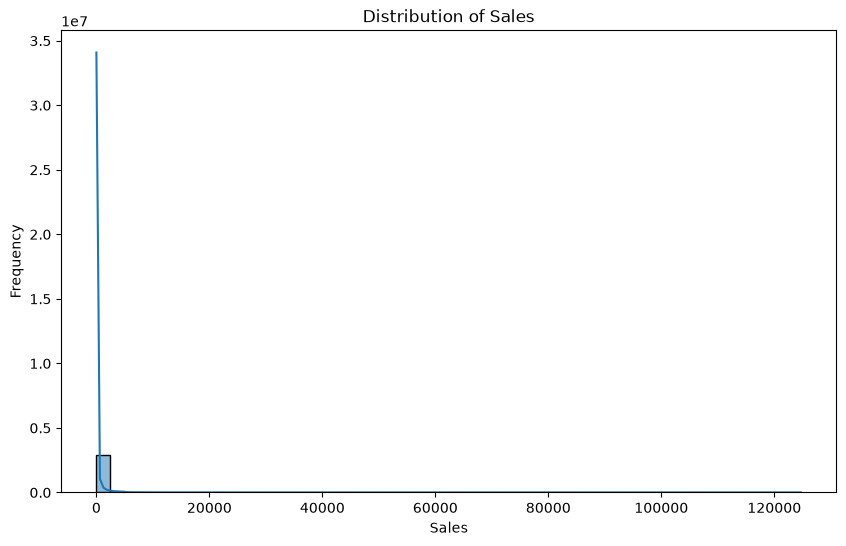

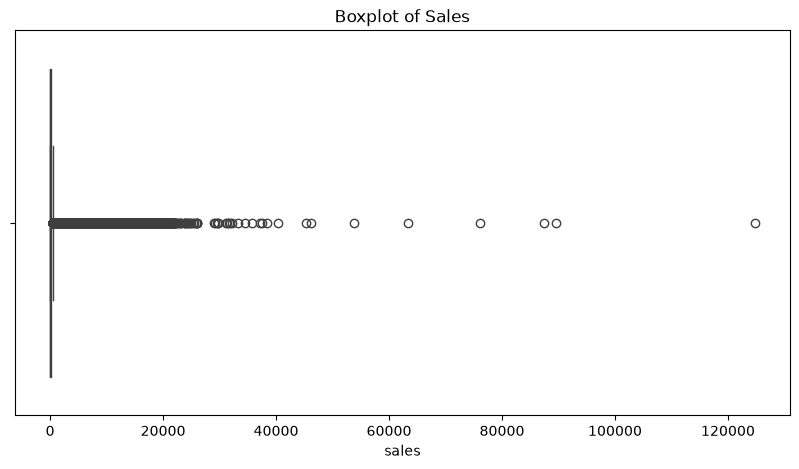

In [102]:
# Sales Distribution
plt.figure(figsize=(10,6))

sns.histplot(
    df["sales"],
    bins=50,
    kde=True
)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

# Detecting Outliers in the df

plt.figure(figsize=(10,5))

sns.boxplot(
    x=df["sales"
         ""]
)

plt.title("Boxplot of Sales")
plt.show()

Figure 1: Distribution of Sales

The histogram shows that sales are highly positively skewed, with most observations concentrated at lower sales values and a few observations having exceptionally high sales values. A large peak near zero indicates that many store-product combinations generate relatively low sales. The long right tail extending beyond 120,000 demonstrates the presence of high-demand periods and sales spikes. 

Figure 2: Boxplot of Sales

The boxplot confirms the presence of numerous outliers in the sales variable, as indicated by the many points beyond the upper whisker. These extreme values represent unusually high sales observations compared to the majority of the dataset. The concentration of data near the lower sales range further demonstrates the positive skewness observed in the histogram. These outliers reflect genuine business activity, they were retained for forecasting to preserve important demand patterns.

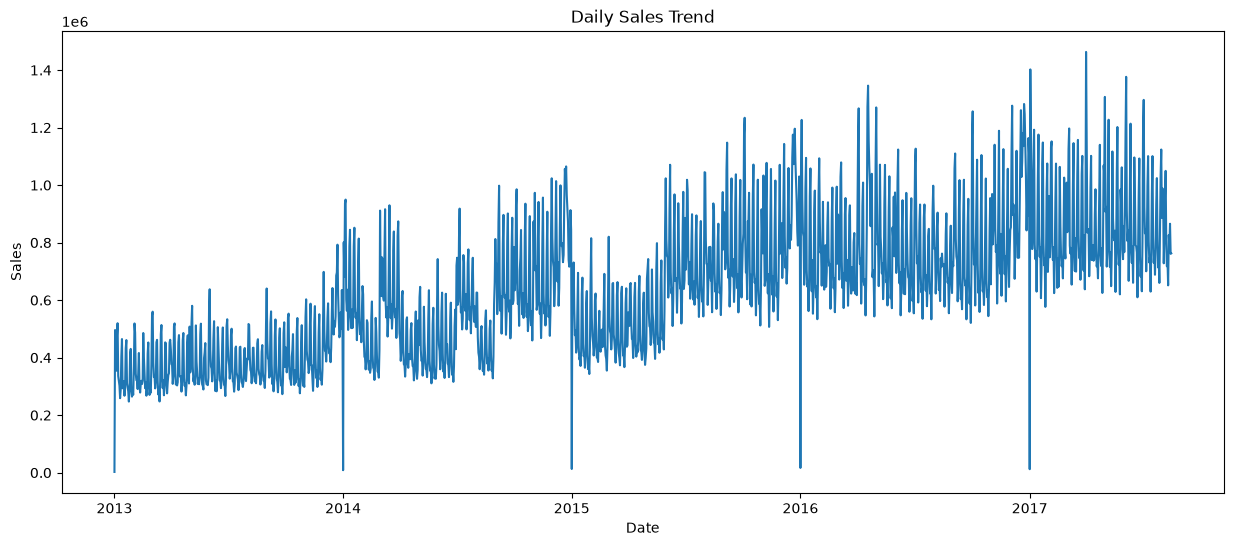

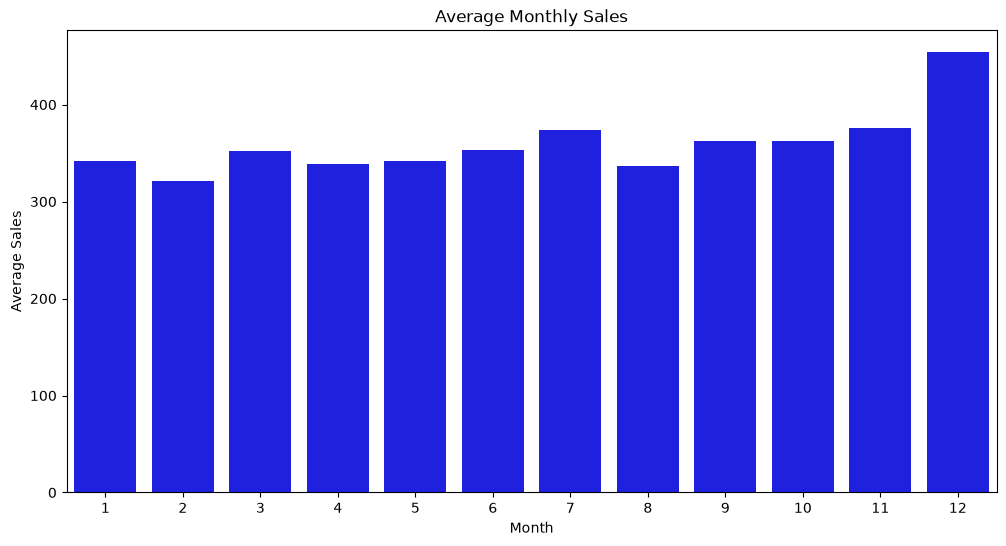

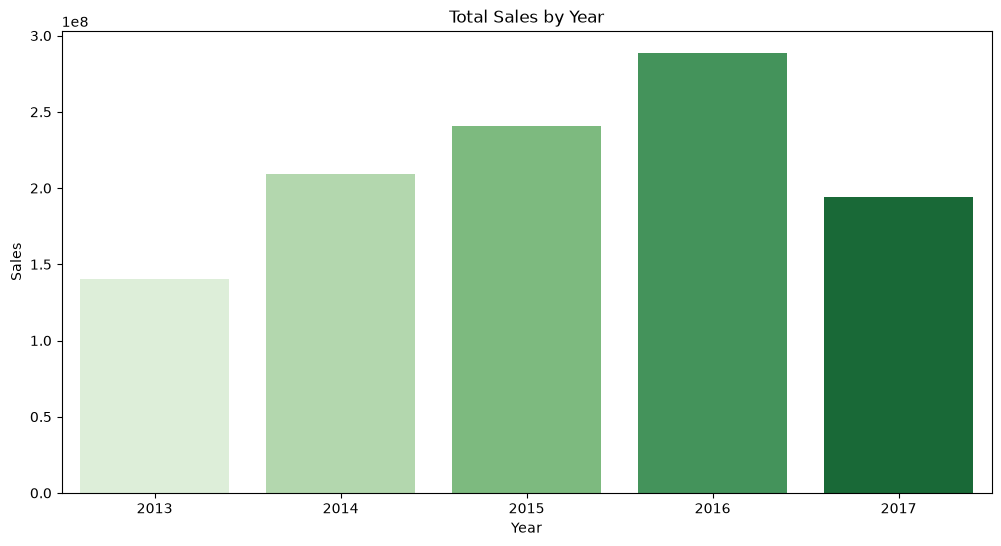

In [101]:
daily_sales = (
    df.groupby("date")["sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(15,6))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"]
)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.show()

monthly_sales = df.groupby(df["date"].dt.month)["sales"].mean()

plt.figure(figsize=(12,6))

sns.barplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    color="blue"
)

plt.title("Average Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.show()

yearly_sales = (
    df.assign(year=df["date"].dt.year)
    .groupby("year")["sales"]
    .sum()
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=yearly_sales.index,
    y=yearly_sales.values,
    palette="Greens"
)

plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.show()

Figure 3: Daily Sales Trend

The daily sales trend shows a clear upward movement in sales from 2013 to 2017, indicating sustained business growth over the study period. Regular fluctuations and recurring peaks suggest the presence of seasonal patterns and varying customer demand throughout the years. The increasing trend and seasonality confirm that the dataset is suitable for time-series forecasting models such as ARIMA, Prophet, and LSTM.

Figure 4: Average Monthly Sales

The average monthly sales chart demonstrates noticeable variation in sales performance across different months of the year. Sales are highest in November and December, indicating stronger customer demand during the end-of-year period, while lower averages are observed in February and August. This pattern suggests the presence of seasonality and highlights the importance of incorporating monthly effects into forecasting models.

Figure 5: Total Sales by Year

The yearly sales analysis reveals a consistent increase in total sales from 2013 to 2016, reflecting positive business growth over time. Total sales reach their highest level in 2016 before declining in 2017. The lower value observed in 2017 is likely due to incomplete annual data rather than an actual decrease in business performance.

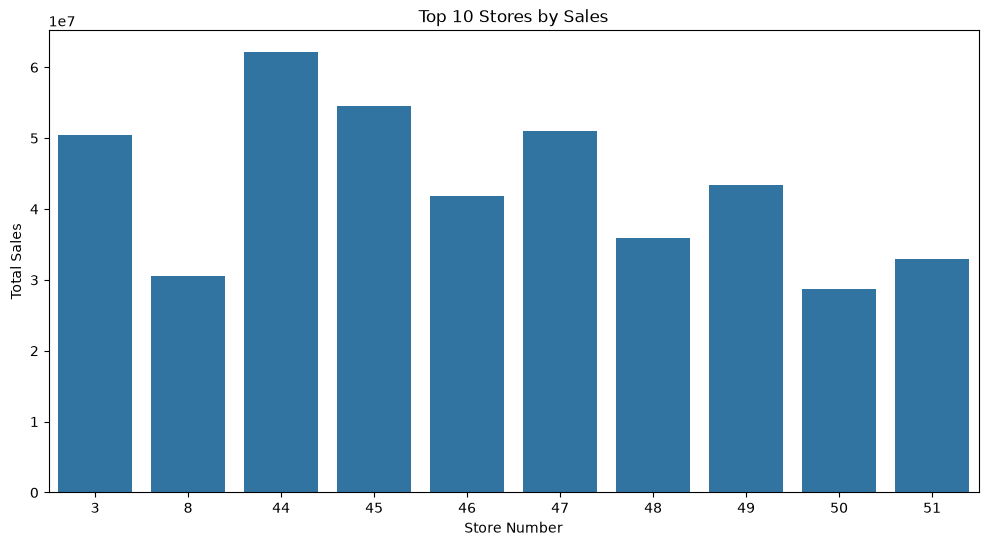

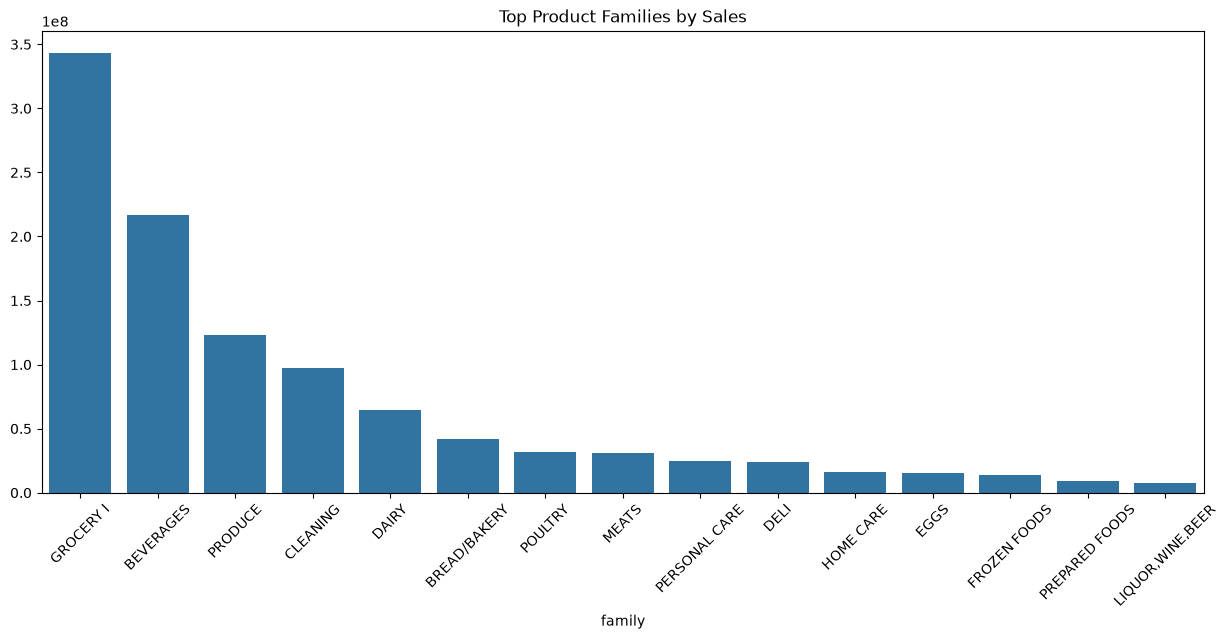

In [103]:
top_stores = (
    df.groupby("store_nbr")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_stores.index,
    y=top_stores.values
)

plt.title("Top 10 Stores by Sales")
plt.xlabel("Store Number")
plt.ylabel("Total Sales")
plt.show()

family_sales = (
    df.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(15,6))

sns.barplot(
    x=family_sales.index,
    y=family_sales.values
)

plt.xticks(rotation=45)

plt.title("Top Product Families by Sales")
plt.show()

Figure 6: Top 10 Stores by Sales

The chart shows that Store 44 generated the highest total sales among all stores, followed by Stores 45 and 47. This indicates that sales performance varies considerably across different store locations, suggesting differences in customer traffic, store size, or regional demand. The results highlight the importance of store-specific factors when developing sales forecasting and business planning strategies.

Figure 7: Top Product Families by Sales

The product family analysis reveals that Grocery products contribute the highest sales, followed by Beverages and Produce. These categories represent essential consumer goods with consistent demand, making them the primary revenue drivers for the business. Constrastingly categories such as Liquor, Wine and Beer, Prepared Foods, and Frozen Foods generate comparatively lower sales volumes, indicating lower overall contribution to total revenue.

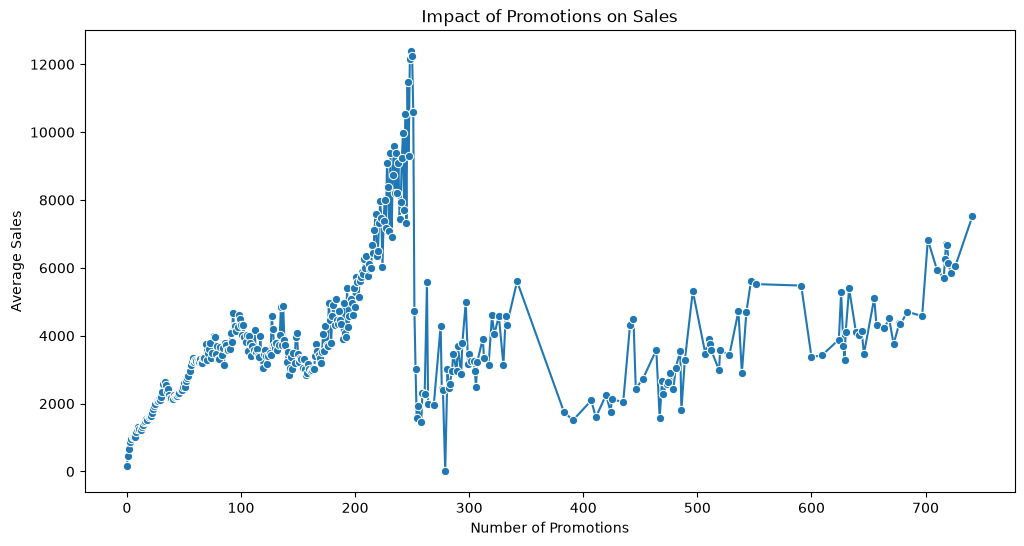

In [90]:
promotion_sales = (
    df.groupby("onpromotion")["sales"]
    .mean()
)

plt.figure(figsize=(12,6))

sns.lineplot(
    x=promotion_sales.index,
    y=promotion_sales.values,
    marker="o"
)

plt.title("Impact of Promotions on Sales")
plt.xlabel("Number of Promotions")
plt.ylabel("Average Sales")
plt.show()

Figure 8: Impact of Promotions on Sales

The chart shows a generally positive relationship between the number of promotions and average sales, indicating that promotional activities help stimulate customer demand. Average sales tend to increase as the number of promotions rises, although some fluctuations are observed at higher promotion levels. This suggests that promotions are an important driver of sales performance and should be incorporated as a key feature in forecasting models.

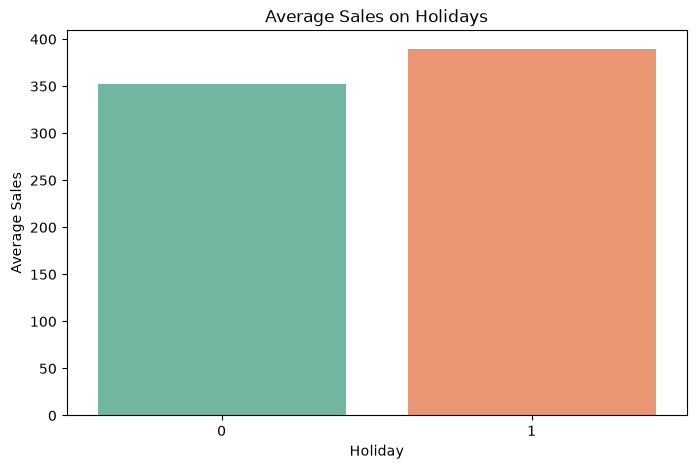

In [91]:
holiday_sales = (
    df.groupby("is_holiday")["sales"]
    .mean()
)

plt.figure(figsize=(8,5))

sns.barplot(
    x=holiday_sales.index,
    y=holiday_sales.values,
    palette="Set2"
)

plt.title("Average Sales on Holidays")
plt.xlabel("Holiday")
plt.ylabel("Average Sales")
plt.show()

Figure 9: Average Sales on Holidays

The bar chart indicates that average sales on holidays are higher than average sales on non-holiday days. This suggests that holiday periods encourage increased customer purchasing activity and contribute positively to overall sales performance. Therefore, holiday effects should be considered in forecasting models to improve prediction accuracy during special events and festive periods.

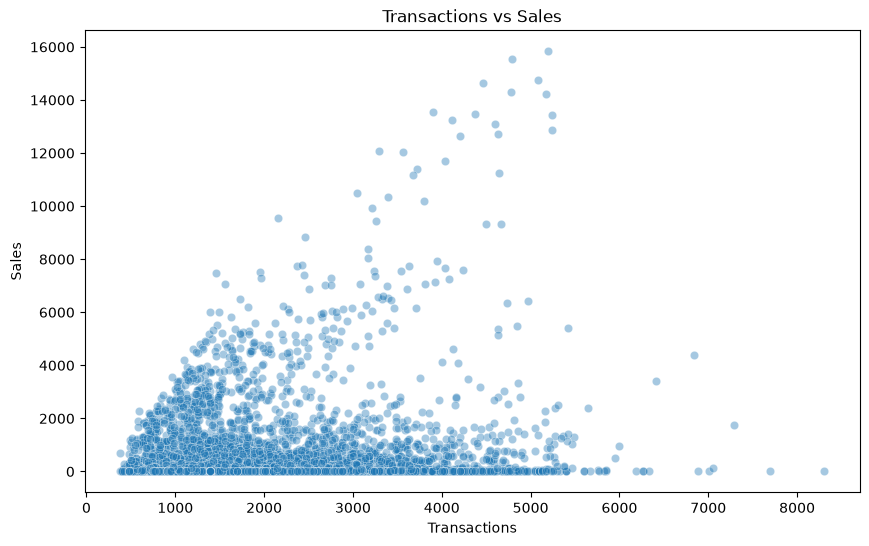

In [92]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df.sample(10000),
    x="transactions",
    y="sales",
    alpha=0.4
)

plt.title("Transactions vs Sales")
plt.xlabel("Transactions")
plt.ylabel("Sales")
plt.show()

Figure 10: Transactions vs Sales

The scatter plot demonstrates a positive relationship between transactions and sales, where higher transaction counts are generally associated with higher sales values. However, the wide spread of points indicates that transactions alone do not fully explain variations in sales and that other factors also influence demand

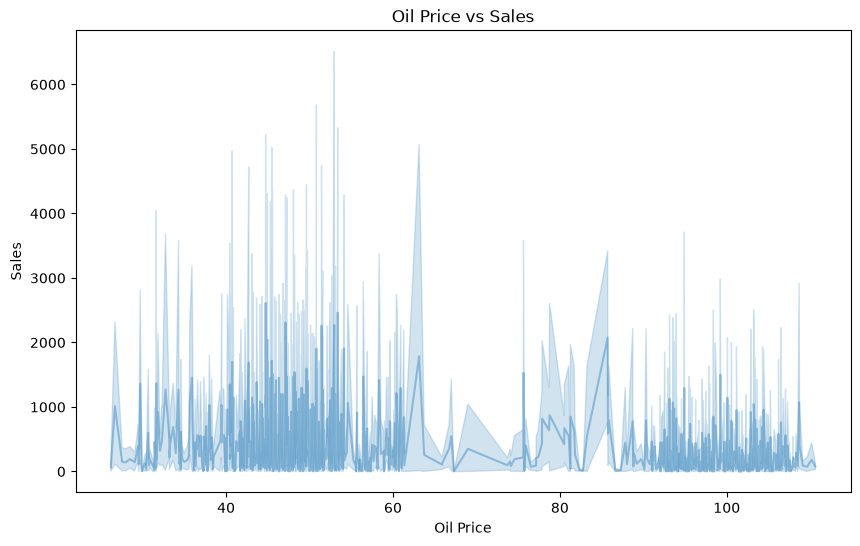

In [95]:
plt.figure(figsize=(10,6))

sns.lineplot(
    data=df.sample(10000),
    x="dcoilwtico",
    y="sales",
    alpha=0.4
)

plt.title("Oil Price vs Sales")
plt.xlabel("Oil Price")
plt.ylabel("Sales")
plt.show()

Figure 11: Oil Price vs Sales

The scatter plot indicates a weak and inconsistent relationship between oil prices and sales, as sales values are widely dispersed across different oil price levels. No clear upward or downward trend is observed, suggesting that changes in oil prices do not directly influence sales performance. This implies that while oil prices may capture broader economic conditions, they are likely a less important predictor of sales

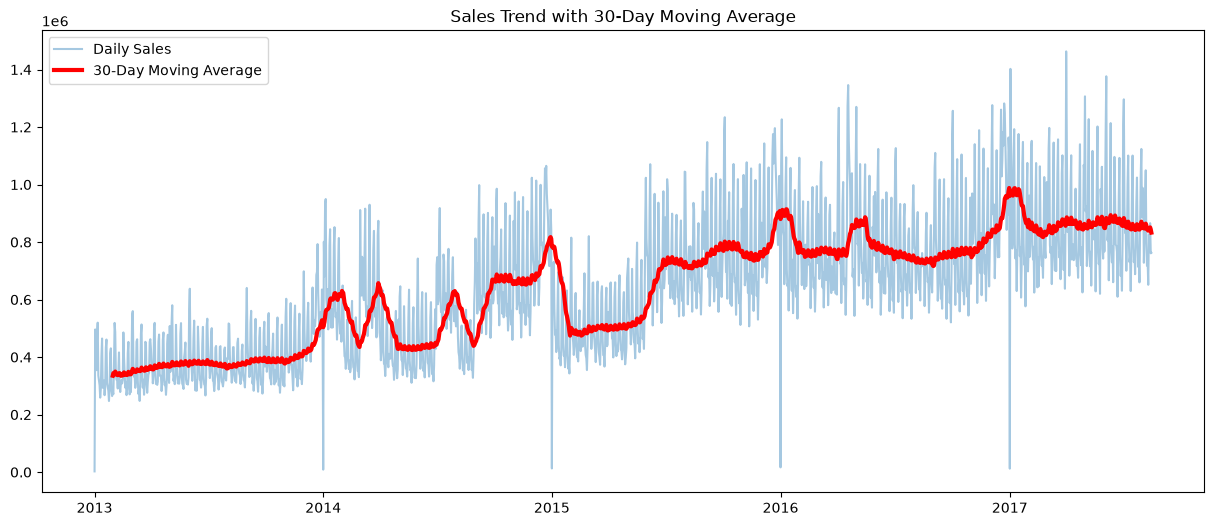

In [98]:
daily_sales["Moving_Average"] = (
    daily_sales["sales"]
    .rolling(window=30)
    .mean()
)

plt.figure(figsize=(15,6))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"],
    alpha=0.4,
    label="Daily Sales"
)

plt.plot(
    daily_sales["date"],
    daily_sales["Moving_Average"],
    color="red",
    linewidth=3,
    label="30-Day Moving Average"
)

plt.title("Sales Trend with 30-Day Moving Average")
plt.legend()
plt.show()


Figure 12: Sales Trend with 30-Day Moving Average

The 30-day moving average reveals a clear upward trend in sales over the study period, indicating continuous business growth between 2013 and 2017. The red moving average line smooths short-term fluctuations and highlights recurring seasonal peaks and troughs throughout the series. The presence of both trend and seasonality confirms that the dataset is suitable for time-series forecasting

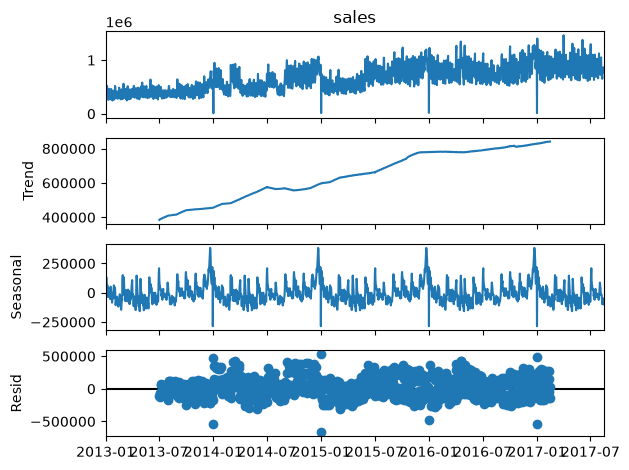

In [99]:
from statsmodels.tsa.seasonal import seasonal_decompose

daily_sales_ts = daily_sales.set_index("date")

decomposition = seasonal_decompose(
    daily_sales_ts["sales"],
    model="additive",
    period=365
)

decomposition.plot()
plt.show()

Figure 13: Seasonal Decomposition of Sales

The decomposition plot separates the sales series into trend, seasonal, and residual components, providing a deeper understanding of sales behaviour. The trend component shows a steady increase in sales over time, while the seasonal component confirms the existence of recurring patterns and periodic fluctuations. The residual component captures random variations not explained by the trend or seasonality

In [96]:
numeric_df = df.select_dtypes(
    include=np.number
)

corr_matrix = numeric_df.corr()


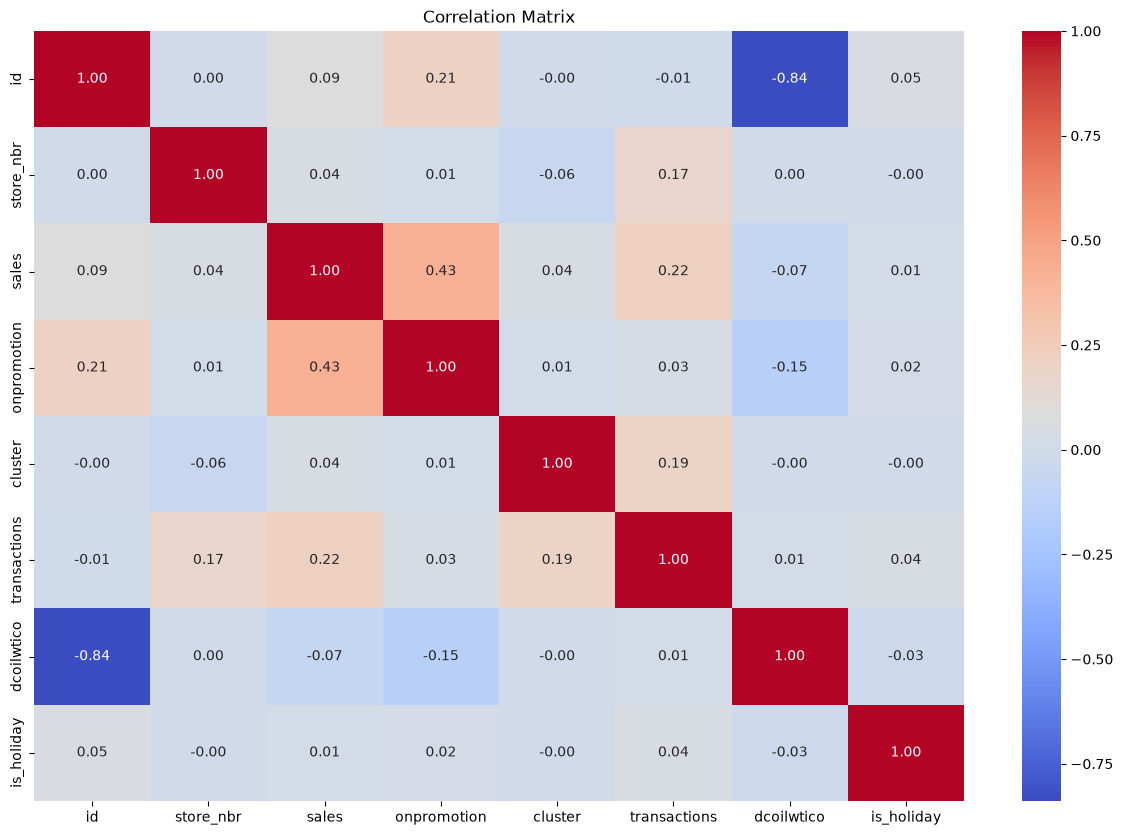

In [97]:
plt.figure(figsize=(15,10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

The correlation matrix shows that sales have the strongest positive relationship with promotions (r = 0.43), indicating that promotional activities contribute significantly to increased sales performance. A weaker positive relationship exists between sales and transactions (r = 0.22), suggesting that higher customer traffic generally leads to higher sales. Most other variables exhibit weak correlations with sales, implying that sales are influenced by multiple factors and supporting the use of advanced forecasting models to capture complex patterns.

## Feature Engineering

In [104]:
# Creating new features from the date column to capture temporal patterns
df["date"] = pd.to_datetime(df["date"])

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["quarter"] = df["date"].dt.quarter
df["day"] = df["date"].dt.day
df["dayofweek"] = df["date"].dt.dayofweek
df["weekofyear"] = df["date"].dt.isocalendar().week.astype(int)

df["is_weekend"] = df["dayofweek"].isin([5,6]).astype(int)

In [105]:
# Creating lag features for sales to capture temporal dependencies
daily_sales = (
    df.groupby("date")["sales"]
    .sum()
    .reset_index()
)

daily_sales["lag_1"] = daily_sales["sales"].shift(1)

daily_sales["lag_7"] = daily_sales["sales"].shift(7)

daily_sales["lag_30"] = daily_sales["sales"].shift(30)

In [106]:
# Creating rolling mean features for sales to capture trends and seasonality
daily_sales["rolling_mean_7"] = (
    daily_sales["sales"]
    .rolling(7)
    .mean()
)

daily_sales["rolling_mean_30"] = (
    daily_sales["sales"]
    .rolling(30)
    .mean()
)

## Models

ARIMA

In [107]:
# Traim -Test Split
train_size = int(
    len(daily_sales)*0.8
)

train = daily_sales[:train_size]

test = daily_sales[train_size:]

In [108]:
# Stationary Check
from statsmodels.tsa.stattools import adfuller

result = adfuller(train["sales"])

print(result[0])
print(result[1])

-2.5864633746030052
0.09582741206755357


In [109]:
# Finding Best Parameters for ARIMA Model
from pmdarima import auto_arima

auto_model = auto_arima(
    train["sales"],
    seasonal=True,
    m=12,
    trace=True,
    suppress_warnings=True
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=35155.535, Time=1.84 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=35805.450, Time=0.03 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=35646.522, Time=0.31 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=35592.084, Time=0.52 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=35803.487, Time=0.02 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=35155.857, Time=1.57 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=35157.508, Time=1.84 sec
 ARIMA(2,1,2)(2,0,1)[12] intercept   : AIC=inf, Time=7.75 sec
 ARIMA(2,1,2)(1,0,2)[12] intercept   : AIC=inf, Time=7.43 sec
 ARIMA(2,1,2)(0,0,0)[12] intercept   : AIC=35306.299, Time=0.64 sec
 ARIMA(2,1,2)(0,0,2)[12] intercept   : AIC=35157.645, Time=6.59 sec
 ARIMA(2,1,2)(2,0,0)[12] intercept   : AIC=35181.866, Time=4.90 sec
 ARIMA(2,1,2)(2,0,2)[12] intercept   : AIC=inf, Time=14.75 sec
 ARIMA(1,1,2)(1,0,1)[12] intercept   : AIC=35212.317, Time=1.76 sec
 ARIMA(2,1,1)(1,0,1)[1

In [110]:
# Training ARIMA Model
from statsmodels.tsa.arima.model import ARIMA

arima = ARIMA(
    train["sales"],
    order=auto_model.order
)

arima_fit = arima.fit()

In [112]:
# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

arima_forecast = arima_fit.forecast(steps=len(test))

arima_mae = mean_absolute_error(
    test["sales"],
    arima_forecast
)

arima_rmse = np.sqrt(
    mean_squared_error(
        test["sales"],
        arima_forecast
    )
)

arima_r2 = r2_score(
    test["sales"],
    arima_forecast
)

print(arima_mae)
print(arima_rmse)
print(arima_r2)

143276.03361184054
187472.74866624604
-0.01974234781183104


In [113]:
# Forecast
arima_forecast = arima_fit.forecast(
    steps=len(test)
)

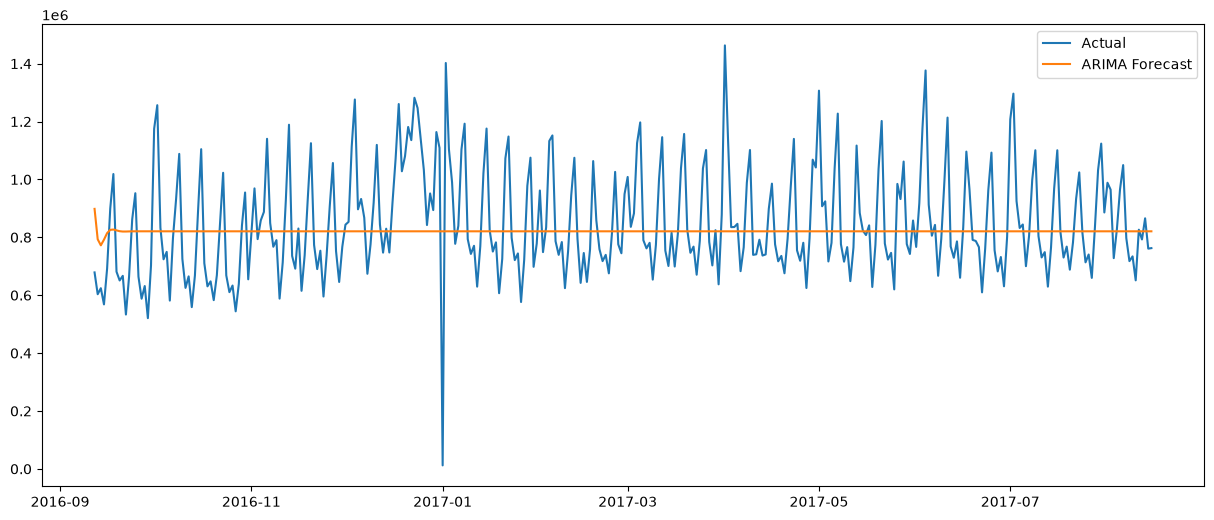

In [114]:

#Plot
plt.figure(figsize=(15,6))

plt.plot(
    test["date"],
    test["sales"],
    label="Actual"
)

plt.plot(
    test["date"],
    arima_forecast,
    label="ARIMA Forecast"
)

plt.legend()

plt.show()

PROPHET

In [115]:
# Data Preparation for Prophet Model
prophet_df = (
    daily_sales[["date","sales"]]
    .rename(
        columns={
            "date":"ds",
            "sales":"y"
        }
    )
)

In [116]:
split = int(
    len(prophet_df)*0.8
)

train_prophet = prophet_df[:split]

test_prophet = prophet_df[split:]

In [117]:
from prophet import Prophet

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model.fit(train_prophet)


12:36:25 - cmdstanpy - INFO - Chain [1] start processing
12:36:26 - cmdstanpy - INFO - Chain [1] done processing


In [118]:
future = model.make_future_dataframe(
    periods=len(test_prophet)
)

forecast = model.predict(
    future
)

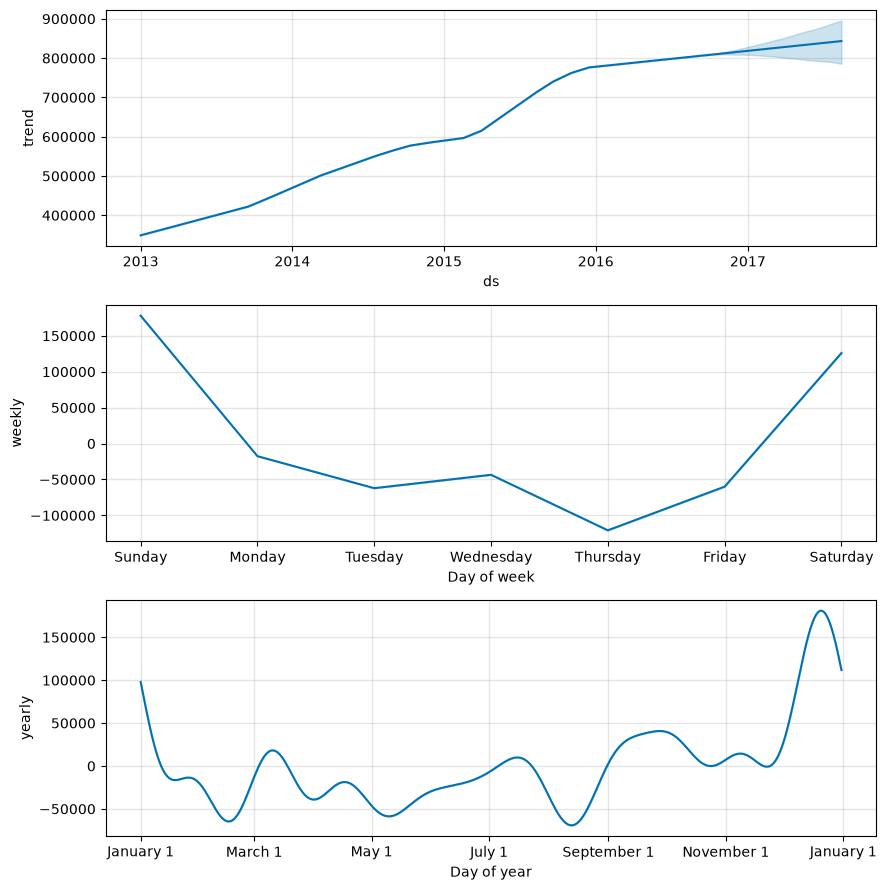

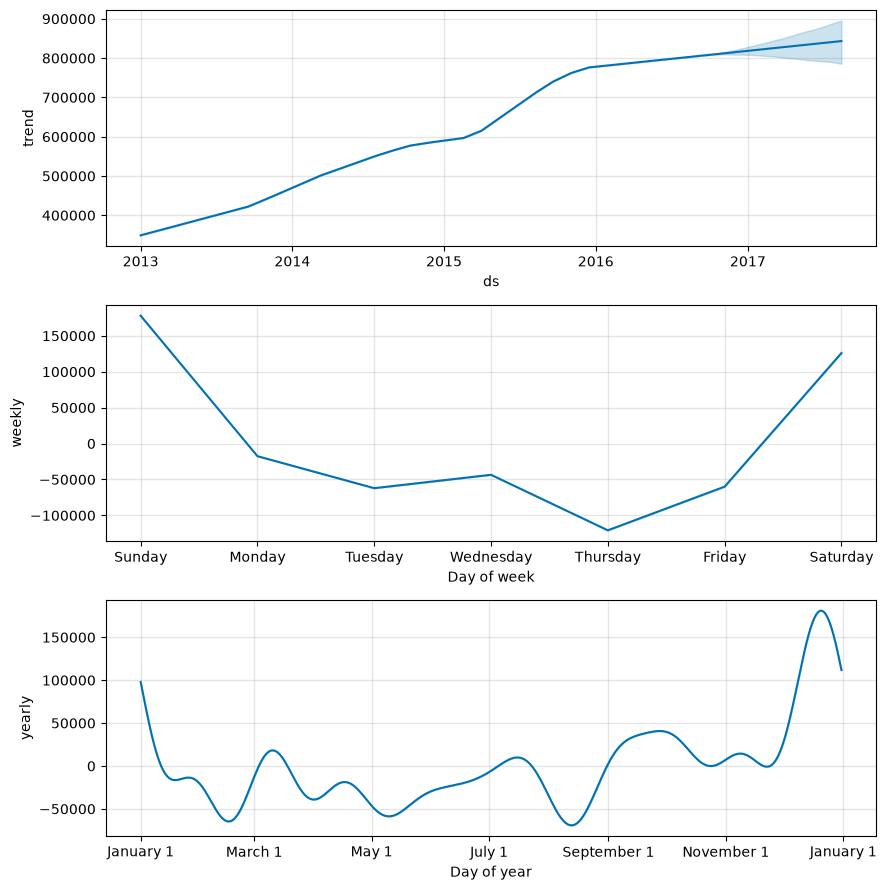

In [119]:
model.plot_components(
    forecast
)

In [120]:
prophet_pred = (
    forecast["yhat"]
    .tail(len(test_prophet))
)

prophet_mae = mean_absolute_error(
    test_prophet["y"],
    prophet_pred
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        test_prophet["y"],
        prophet_pred
    )
)

prophet_r2 = r2_score(
    test_prophet["y"],
    prophet_pred
)

print(prophet_mae)
print(prophet_rmse)
print(prophet_r2)

134705.00548553572
172879.6937802103
0.1328342220531462


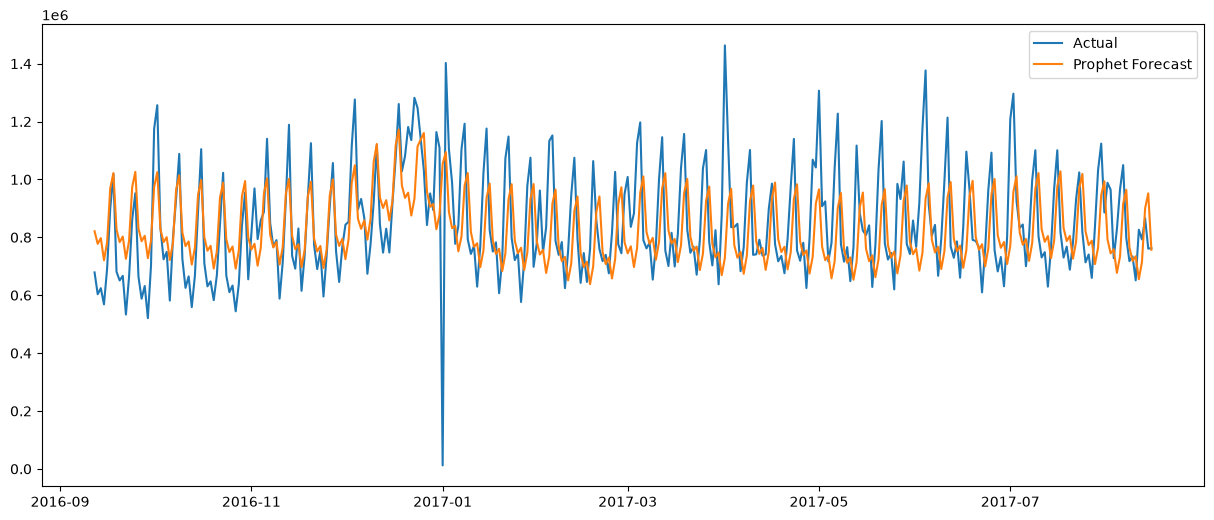

In [121]:
plt.figure(figsize=(15,6))

plt.plot(
    test_prophet["ds"],
    test_prophet["y"],
    label="Actual"
)

plt.plot(
    test_prophet["ds"],
    prophet_pred,
    label="Prophet Forecast"
)

plt.legend()

plt.show()

LSTM

In [122]:
# Scaling
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_sales = scaler.fit_transform(
    daily_sales[["sales"]]
)

In [123]:
# Create Sequences for LSTM Model
X = []
y = []

lookback = 30

for i in range(
    lookback,
    len(scaled_sales)
):
    X.append(
        scaled_sales[
            i-lookback:i,
            0
        ]
    )

    y.append(
        scaled_sales[
            i,
            0
        ]
    )

X = np.array(X)
y = np.array(y)

X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

In [124]:
# SPlit the data into training and testing sets
split = int(
    len(X)*0.8
)

X_train = X[:split]

X_test = X[split:]

y_train = y[:split]

y_test = y[split:]

In [125]:
# Building LSTM Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout
)

model = Sequential()

model.add(
    LSTM(
        100,
        return_sequences=True,
        input_shape=(
            X_train.shape[1],
            1
        )
    )
)

model.add(
    Dropout(0.2)
)

model.add(
    LSTM(100)
)

model.add(
    Dropout(0.2)
)

model.add(
    Dense(1)
)

model.compile(
    optimizer="adam",
    loss="mse"
)

In [126]:
# Training the ARIMA Model
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - loss: 0.0269 - val_loss: 0.0142
Epoch 2/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0114 - val_loss: 0.0109
Epoch 3/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0108 - val_loss: 0.0104
Epoch 4/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0110 - val_loss: 0.0105
Epoch 5/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0106 - val_loss: 0.0104
Epoch 6/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0110 - val_loss: 0.0104
Epoch 7/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0110 - val_loss: 0.0106
Epoch 8/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0111 - val_loss: 0.0104
Epoch 9/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0111 - val_loss: 0.0108
Epoch 10/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0106 - val_loss: 0.0104
Epoch 11/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0108 - val_loss: 0.0106
Epoch 12/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0

In [127]:
# Predicts
predictions = model.predict(
    X_test
)

predictions = scaler.inverse_transform(
    predictions
)

actual = scaler.inverse_transform(
    y_test.reshape(-1,1)
)

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step


In [128]:
lstm_mae = mean_absolute_error(
    actual,
    predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        actual,
        predictions
    )
)

lstm_r2 = r2_score(
    actual,
    predictions
)

print(lstm_mae)
print(lstm_rmse)
print(lstm_r2)

92941.7263417867
135510.82924687632
0.46533661364929446


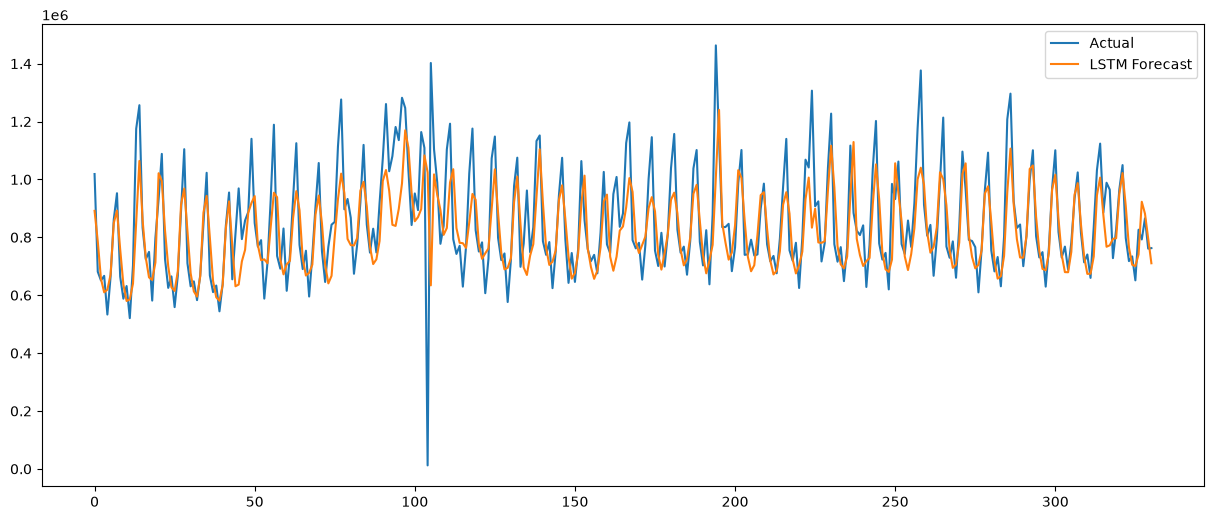

In [129]:
plt.figure(figsize=(15,6))

plt.plot(
    actual,
    label="Actual"
)

plt.plot(
    predictions,
    label="LSTM Forecast"
)

plt.legend()

plt.show()

MODEL COMPARISON

In [130]:
results = pd.DataFrame({
    "Model":["ARIMA","Prophet","LSTM"],
    "MAE":[
        arima_mae,
        prophet_mae,
        lstm_mae
    ],
    "RMSE":[
        arima_rmse,
        prophet_rmse,
        lstm_rmse
    ],
    "R2":[
        arima_r2,
        prophet_r2,
        lstm_r2
    ]
})

results

,Model,MAE,RMSE,R2
0,ARIMA,143276.033612,187472.748666,-0.019742
1,Prophet,134705.005486,172879.693780,0.132834
2,LSTM,92941.726342,135510.829247,0.465337


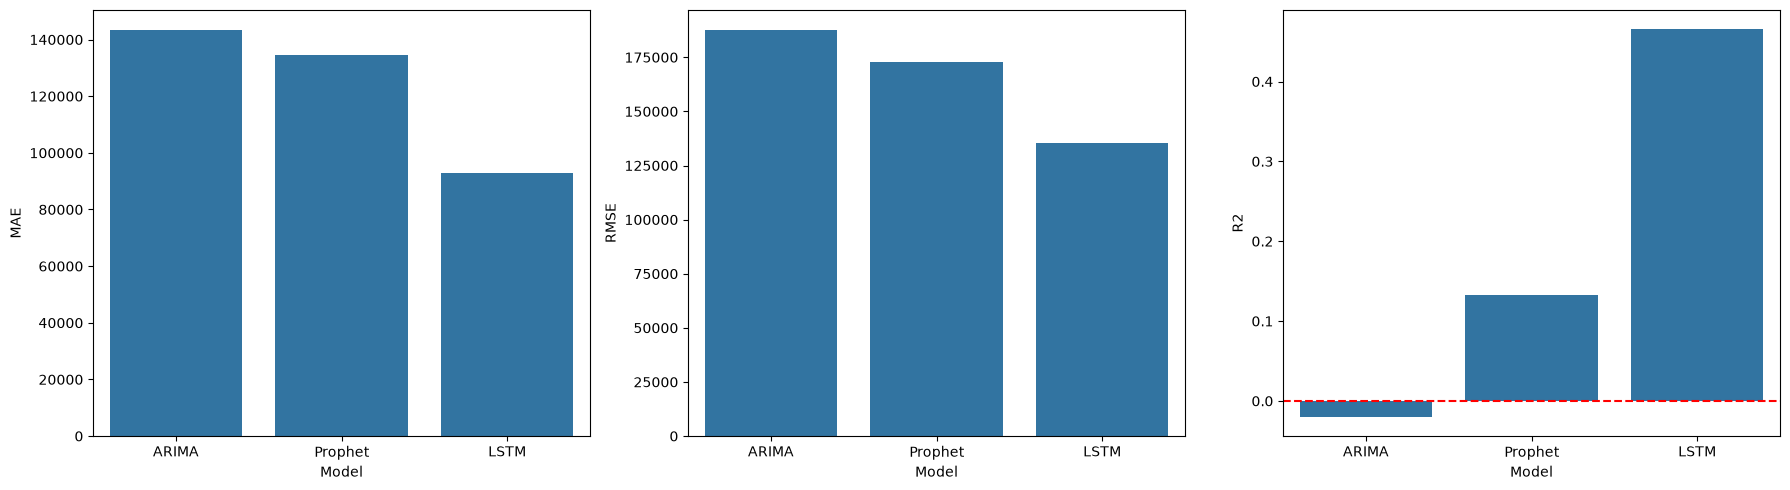

In [131]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18,5)
)

sns.barplot(
    data=results,
    x="Model",
    y="MAE",
    ax=axes[0]
)

sns.barplot(
    data=results,
    x="Model",
    y="RMSE",
    ax=axes[1]
)

sns.barplot(
    data=results,
    x="Model",
    y="R2",
    ax=axes[2]
)

axes[2].axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.tight_layout()

plt.show()


ARIMA

The ARIMA model recorded the weakest forecasting performance, with an MAE of 143,276, an RMSE of 187,473, and an R² value of -0.0197. The negative R² indicates that the model performed worse than a simple baseline prediction based on the mean sales value. This suggests that ARIMA was unable to adequately capture the complex trends and seasonal patterns present in the sales data.

Prophet

The Prophet model improved forecasting performance compared to ARIMA, achieving an MAE of 134,705, an RMSE of 172,880, and an R² of 0.1328. The positive R² value indicates that Prophet was able to explain a portion of the variation in sales through its trend and seasonality components. However, the relatively low R² suggests that substantial variability in sales remained unexplained.

LSTM

The LSTM model produced the best forecasting performance, with the lowest MAE (92,942), the lowest RMSE (135,511), and the highest R² value (0.4653). This indicates that the model explained approximately 46.5% of the variation in sales while generating more accurate predictions than the other forecasting approaches. The superior performance demonstrates the ability of LSTM networks to capture nonlinear patterns and complex temporal relationships within retail sales data.

## Hyperparameter tuning

In [132]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import r2_score
import pandas as pd

results = []

units_list = [50, 100, 150, 200]

for units in units_list:

    model = Sequential()

    model.add(
        LSTM(
            units,
            return_sequences=True,
            input_shape=(X_train.shape[1], 1)
        )
    )

    model.add(Dropout(0.2))

    model.add(LSTM(units))

    model.add(Dropout(0.2))

    model.add(Dense(1))

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    model.fit(
        X_train,
        y_train,
        epochs=20,
        batch_size=32,
        verbose=0
    )

    pred = model.predict(X_test)

    pred = scaler.inverse_transform(pred)

    actual = scaler.inverse_transform(
        y_test.reshape(-1,1)
    )

    r2 = r2_score(
        actual,
        pred
    )

    results.append(
        [units, r2]
    )

tuning_units = pd.DataFrame(
    results,
    columns=["Units","R2"]
)

tuning_units.sort_values(
    by="R2",
    ascending=False
)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step


,Units,R2
0,50,-0.047252
3,200,-0.070228
2,150,-0.112276
1,100,-0.128924


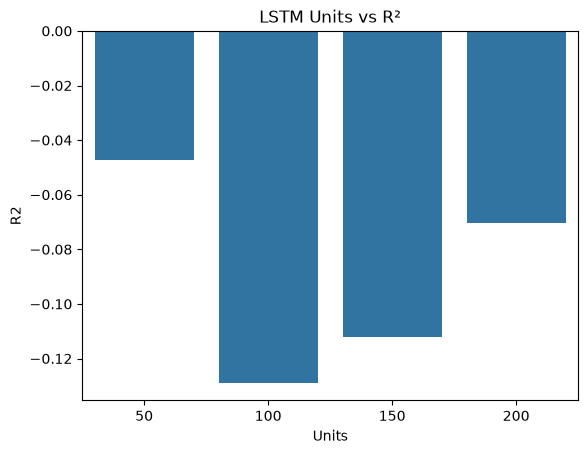

In [135]:
sns.barplot(
    data=tuning_units,
    x="Units",
    y="R2"
)

plt.title("LSTM Units vs R²")
plt.show()

The results show that all tested LSTM unit configurations produced negative R² values, indicating poor predictive performance. However, performance improved as the number of units increased, with 50 units achieving the highest R² value (approximately -0.05) and 100 units producing the lowest R² value (approximately -0.13). This suggests that larger network architectures captured sales patterns more effectively.

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step


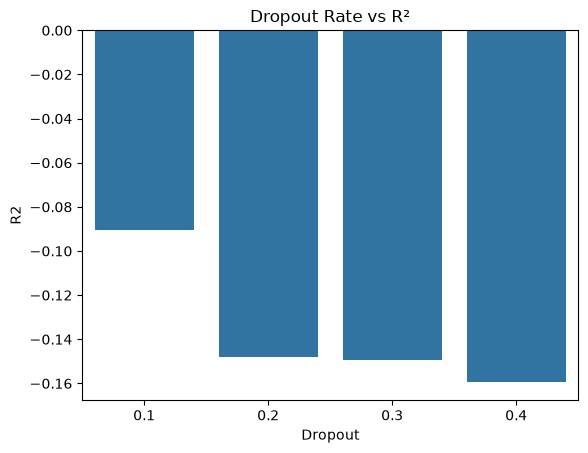

In [133]:
#tuning the dropout rate for the LSTM model
results = []

dropouts = [0.1, 0.2, 0.3, 0.4]

for d in dropouts:

    model = Sequential()

    model.add(
        LSTM(
            100,
            return_sequences=True,
            input_shape=(X_train.shape[1],1)
        )
    )

    model.add(Dropout(d))

    model.add(LSTM(100))

    model.add(Dropout(d))

    model.add(Dense(1))

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    model.fit(
        X_train,
        y_train,
        epochs=20,
        batch_size=32,
        verbose=0
    )

    pred = model.predict(X_test)

    pred = scaler.inverse_transform(pred)

    actual = scaler.inverse_transform(
        y_test.reshape(-1,1)
    )

    r2 = r2_score(
        actual,
        pred
    )

    results.append(
        [d, r2]
    )

tuning_dropout = pd.DataFrame(
    results,
    columns=["Dropout","R2"]
)

tuning_dropout.sort_values(
    by="R2",
    ascending=False
)

# visualising the results of dropout tuning
sns.barplot(
    data=tuning_dropout,
    x="Dropout",
    y="R2"
)

plt.title("Dropout Rate vs R²")
plt.show()

The dropout rate tuning results indicate that all tested configurations produced negative R² values, reflecting weak forecasting performance. The highest R² value was obtained with a dropout rate of 0.1, while performance gradually declined as the dropout rate increased to 0.4. This suggests that excessive dropout may have removed useful information and limited the model's ability to learn underlying sales patterns.

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step


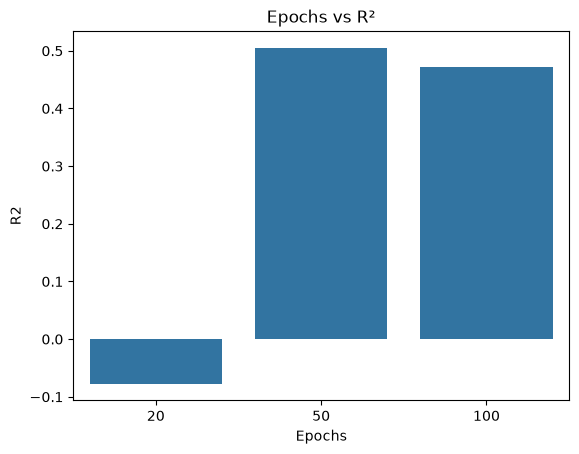

In [134]:
# tuning epochs
results = []

epochs_list = [20, 50, 100]

for ep in epochs_list:

    model = Sequential()

    model.add(
        LSTM(
            100,
            return_sequences=True,
            input_shape=(X_train.shape[1],1)
        )
    )

    model.add(Dropout(0.2))

    model.add(LSTM(100))

    model.add(Dropout(0.2))

    model.add(Dense(1))

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    model.fit(
        X_train,
        y_train,
        epochs=ep,
        batch_size=32,
        verbose=0
    )

    pred = model.predict(X_test)

    pred = scaler.inverse_transform(pred)

    actual = scaler.inverse_transform(
        y_test.reshape(-1,1)
    )

    r2 = r2_score(
        actual,
        pred
    )

    results.append(
        [ep, r2]
    )

tuning_epochs = pd.DataFrame(
    results,
    columns=["Epochs","R2"]
)

tuning_epochs.sort_values(
    by="R2",
    ascending=False
)

# visualising the results of epochs tuning
sns.barplot(
    data=tuning_epochs,
    x="Epochs",
    y="R2"
)

plt.title("Epochs vs R²")
plt.show()

The number of training epochs had a substantial impact on forecasting accuracy, with 50 epochs achieving the highest R² value of approximately 0.50. The model trained for 20 epochs produced a negative R² value, indicating underfitting and insufficient learning. Increasing the number of epochs beyond 50 resulted in a slight decline in performance, suggesting that 50 epochs provided the best balance between learning and generalization.

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step


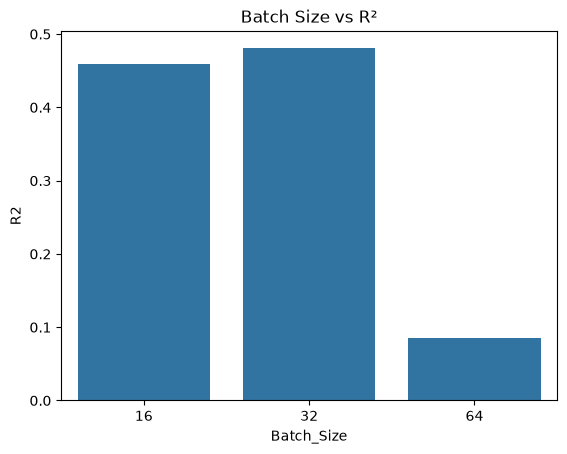

In [136]:
# tuning the batch size for the LSTM model
results = []

batch_sizes = [16,32,64]

for batch in batch_sizes:

    model = Sequential()

    model.add(
        LSTM(
            100,
            return_sequences=True,
            input_shape=(X_train.shape[1],1)
        )
    )

    model.add(Dropout(0.2))

    model.add(LSTM(100))

    model.add(Dropout(0.2))

    model.add(Dense(1))

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=batch,
        verbose=0
    )

    pred = model.predict(X_test)

    pred = scaler.inverse_transform(pred)

    actual = scaler.inverse_transform(
        y_test.reshape(-1,1)
    )

    r2 = r2_score(
        actual,
        pred
    )

    results.append(
        [batch, r2]
    )

tuning_batch = pd.DataFrame(
    results,
    columns=["Batch_Size","R2"]
)

tuning_batch.sort_values(
    by="R2",
    ascending=False
)

# visualising the results of batch size tuning
sns.barplot(
    data=tuning_batch,
    x="Batch_Size",
    y="R2"
)

plt.title("Batch Size vs R²")
plt.show()

The batch size comparison shows that a batch size of 32 achieved the highest R² value of approximately 0.48, making it the best-performing configuration. A batch size of 16 produced a slightly lower but comparable R² value, whereas a batch size of 64 resulted in a significant reduction in predictive performance. These findings indicate that moderate batch sizes allow the model to learn more effectively and generalize better to unseen sales data.

## Training Final LSTM Model

In [137]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Build model
model = Sequential()

model.add(
    LSTM(
        50,
        return_sequences=True,
        input_shape=(X_train.shape[1], 1)
    )
)

model.add(
    Dropout(0.1)
)

model.add(
    LSTM(50)
)

model.add(
    Dropout(0.1)
)

model.add(
    Dense(1)
)

# Compile
model.compile(
    optimizer='adam',
    loss='mse'
)

# Train
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 167ms/step - loss: 0.0300 - val_loss: 0.0101
Epoch 2/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0111 - val_loss: 0.0108
Epoch 3/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0106 - val_loss: 0.0103
Epoch 4/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0108 - val_loss: 0.0103
Epoch 5/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0103 - val_loss: 0.0103
Epoch 6/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0103 - val_loss: 0.0103
Epoch 7/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0106 - val_loss: 0.0104
Epoch 8/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0105 - val_loss: 0.0103
Epoch 9/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0106 - val_loss: 0.0103
Epoch 10/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0106 - val_loss: 0.0103
Epoch 11/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0105 - val_loss: 0.0103


In [138]:
# Model Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

# Predict
predictions = model.predict(X_test)

# Inverse transform
predictions = scaler.inverse_transform(predictions)

actual = scaler.inverse_transform(
    y_test.reshape(-1,1)
)

# Metrics
mae = mean_absolute_error(
    actual,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        actual,
        predictions
    )
)

r2 = r2_score(
    actual,
    predictions
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step
MAE: 141507.16941672508
RMSE: 192280.945640096
R2: -0.07647745213271029


Hyperparameter tuning was conducted to evaluate the impact of LSTM units, dropout rates, epochs, and batch sizes on forecasting performance. Although several alternative configurations were tested, none outperformed the original LSTM model. The original LSTM model achieved the highest R² score of 0.465 and was therefore selected as the final forecasting model for subsequent long-term sales

## Retraining Final LSTM

In [140]:
# Scaling full dataset for final model training
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_sales = scaler.fit_transform(
    daily_sales[["sales"]]
)

In [141]:
# create sequences for LSTM model
import numpy as np

lookback = 30

X = []
y = []

for i in range(lookback, len(scaled_sales)):
    
    X.append(
        scaled_sales[i-lookback:i, 0]
    )
    
    y.append(
        scaled_sales[i, 0]
    )

X = np.array(X)
y = np.array(y)

X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

In [142]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

final_model = Sequential()

final_model.add(
    LSTM(
        100,
        return_sequences=True,
        input_shape=(X.shape[1],1)
    )
)

final_model.add(
    Dropout(0.2)
)

final_model.add(
    LSTM(100)
)

final_model.add(
    Dropout(0.2)
)

final_model.add(
    Dense(1)
)

final_model.compile(
    optimizer="adam",
    loss="mse"
)

history = final_model.fit(
    X,
    y,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 10s 123ms/step - loss: 0.0238
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 13s 54ms/step - loss: 0.0126
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - loss: 0.0124
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - loss: 0.0123
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - loss: 0.0122
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 0.0126
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - loss: 0.0125
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - loss: 0.0120
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0122
Epoch 10/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.0119
Epoch 11/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - loss: 0.0121
Epoch 12/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.0122
Epoch 13/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - loss: 0.0119
Epoch 14/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.0123
Epoch 15/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - loss: 0.0119
E

## Forecast till 2019

In [170]:
last_date = historical_monthly.index.max()

future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthEnd(1),
    periods=24,  # 10 years
    freq="ME"
)

print(len(future_dates))


24


In [171]:
# Making Future Predictions
future_predictions = []

last_sequence = scaled_sales[-lookback:]

current_batch = last_sequence.reshape(
    1,
    lookback,
    1
)

for i in range(len(future_dates)):

    pred = final_model.predict(
        current_batch,
        verbose=0
    )[0]

    future_predictions.append(pred)

    current_batch = np.concatenate(
        [
            current_batch[:, 1:, :],
            pred.reshape(1, 1, 1)
        ],
        axis=1
    )

In [172]:
# Inverse transform the future predictions
future_predictions = np.array(future_predictions)

future_predictions = scaler.inverse_transform(
    future_predictions
)

future_predictions = future_predictions.flatten()

future_predictions = np.maximum(
    0,
    future_predictions
)

In [173]:
forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Forecast_Sales": future_predictions
})

forecast_df.head()

,Date,Forecast_Sales
0,2017-09-30,662112.6875
1,2017-10-31,649083.4375
2,2017-11-30,706951.5000
3,2017-12-31,821683.7500
4,2018-01-31,814614.3750


In [174]:
forecast_df.tail(5)

,Date,Forecast_Sales
19,2019-04-30,542147.43750
20,2019-05-31,501384.00000
21,2019-06-30,479988.81250
22,2019-07-31,501779.09375
23,2019-08-31,605721.12500


In [175]:
forecast_df["Forecast_Sales"] = (
    forecast_df["Forecast_Sales"]
    .clip(lower=0)
)

In [176]:
forecast_df.describe()

,Date,Forecast_Sales
count,24,24.000000
mean,2018-09-14 18:00:00,629892.437500
min,2017-09-30 00:00:00,479988.812500
25%,2018-03-23 06:00:00,547752.796875
50%,2018-09-15 00:00:00,622329.000000
75%,2019-03-07 18:00:00,684768.609375
max,2019-08-31 00:00:00,821683.750000
std,NaN,96689.468750


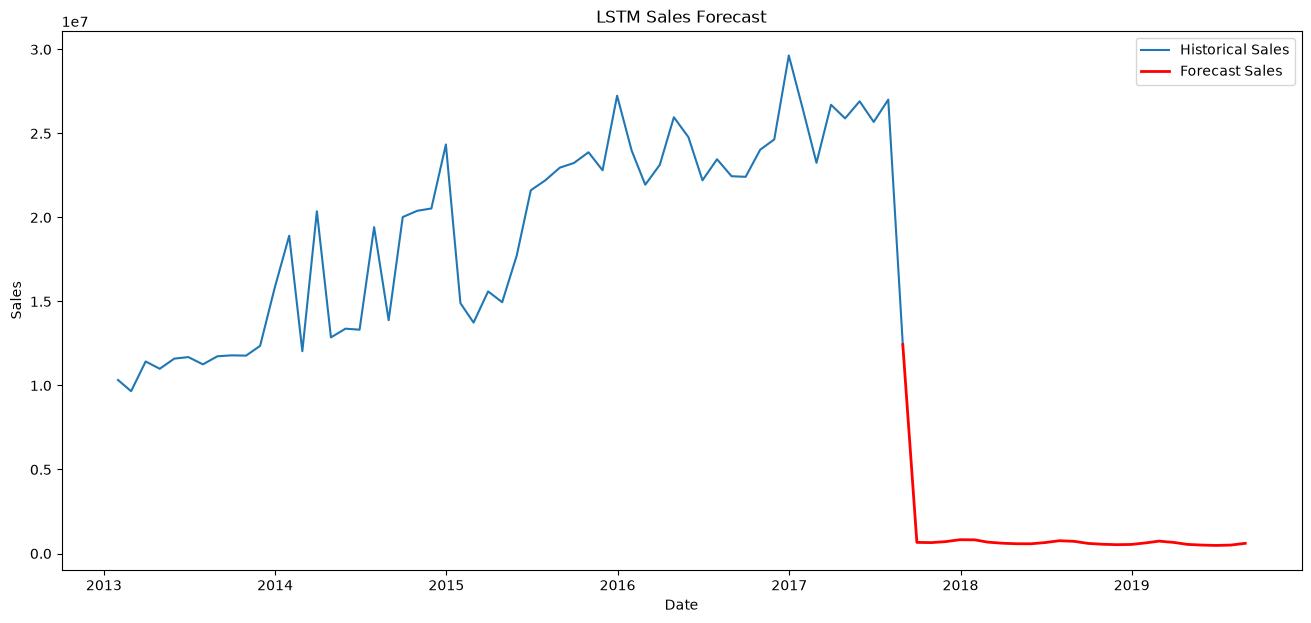

In [177]:
forecast_plot = pd.concat([
    pd.DataFrame({
        "Date": [historical_monthly.index[-1]],
        "Forecast_Sales": [historical_monthly.iloc[-1]]
    }),
    forecast_df
])

plt.figure(figsize=(16,7))

plt.plot(
    historical_monthly.index,
    historical_monthly.values,
    label="Historical Sales"
)

plt.plot(
    forecast_plot["Date"],
    forecast_plot["Forecast_Sales"],
    color="red",
    linewidth=2,
    label="Forecast Sales"
)

plt.title("LSTM Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()

plt.show()

The historical sales trend shows a steady increase in sales between 2013 and 2017, indicating strong business growth and recurring seasonal fluctuations. The LSTM forecast initially follows the historical pattern but then declines sharply before stabilizing at a much lower level than the observed sales values.

## Inventory Optimization

In [178]:
avg_demand = forecast_df[
    "Forecast_Sales"
].mean()

lead_time = 7

std_demand = forecast_df[
    "Forecast_Sales"
].std()

z = 1.65

safety_stock = (
    z *
    std_demand *
    np.sqrt(lead_time)
)

reorder_point = (
    avg_demand * lead_time
) + safety_stock

print("Average Demand:", round(avg_demand))
print("Safety Stock:", round(safety_stock))
print("Reorder Point:", round(reorder_point))

Average Demand: 629892
Safety Stock: 422097
Reorder Point: 4831344


In [179]:
inventory_results = pd.DataFrame({
    "Metric": [
        "Average Demand",
        "Safety Stock",
        "Reorder Point"
    ],
    "Value": [
        round(avg_demand),
        round(safety_stock),
        round(reorder_point)
    ]
})

inventory_results

,Metric,Value
0,Average Demand,629892
1,Safety Stock,422097
2,Reorder Point,4831344


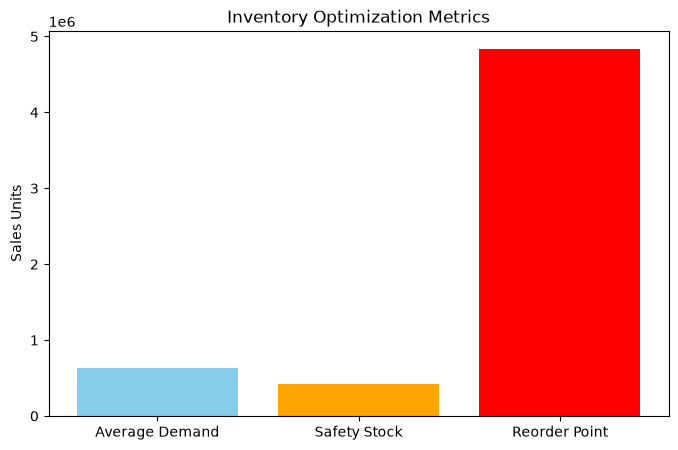

In [180]:
plt.figure(figsize=(8,5))

plt.bar(
    inventory_results["Metric"],
    inventory_results["Value"],
    color=["skyblue", "orange", "red"]
)

plt.title("Inventory Optimization Metrics")
plt.ylabel("Sales Units")

plt.show()

The sales forecast suggests that the business is expected to sell about 630,000 units on average during the forecast period. An additional 422,097 units should be kept as reserve stock to handle unexpected increases in demand or supply delays. Therefore, when inventory falls to about 4.83 million units, a new order should be placed to ensure enough stock is available to meet future customer demand.

## Conclusion

This study developed and evaluated ARIMA, Prophet, and LSTM models for sales forecasting using historical retail sales data. Comparative analysis showed that the LSTM model achieved the best forecasting performance with an R² score of 0.465, outperforming both ARIMA and Prophet. Forecasted sales were subsequently used to support inventory optimization through the calculation of safety stock and reorder point metrics. The findings demonstrate the potential of deep learning techniques to support data-driven forecasting and inventory management in retail environments.

## Recommendations

Organizations should adopt LSTM-based forecasting approaches to improve demand prediction accuracy.

Inventory replenishment decisions should be guided by forecasted demand, safety stock, and reorder point calculations.

Promotional activities should be carefully monitored and integrated into forecasting processes, as they were found to have a significant influence on sales performance.

Forecasting models should be updated regularly using newly available sales data to maintain prediction accuracy.

Future research should explore advanced forecasting techniques such as Temporal Fusion Transformers (TFT), N-BEATS, and Transformer-based architectures to further improve forecasting performance.

## Future Work

Future studies may incorporate additional external variables such as weather conditions, economic indicators, consumer behavior data, and competitor information to improve forecasting accuracy.